In [1]:
# %% STEP 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


In [ ]:
# %% STEP 2: load CSV file

df = pd.read_csv(r"train.csv")   
print("Data shape:", df.shape)
df.head()

Data shape: (42000, 785)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# %% STEP 3: Data Preprocessing
# Label save as y and pixels save as X
y = df.iloc[:, 0].values            
X = df.iloc[:, 1:].values           

# Normalization: pixel values 0-255 to 0-1 range
X = X.astype("float32") / 255.0

# Reshape: 784 -> 28 x 28 x 1 (height, width, channel)
X = X.reshape(-1, 28, 28, 1)

print("X shape:", X.shape, " y shape:", y.shape)

X shape: (42000, 28, 28, 1)  y shape: (42000,)


In [4]:
# %% STEP 4: Training and Validation split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, " Validation:", X_val.shape)

Train: (33600, 28, 28, 1)  Validation: (8400, 28, 28, 1)


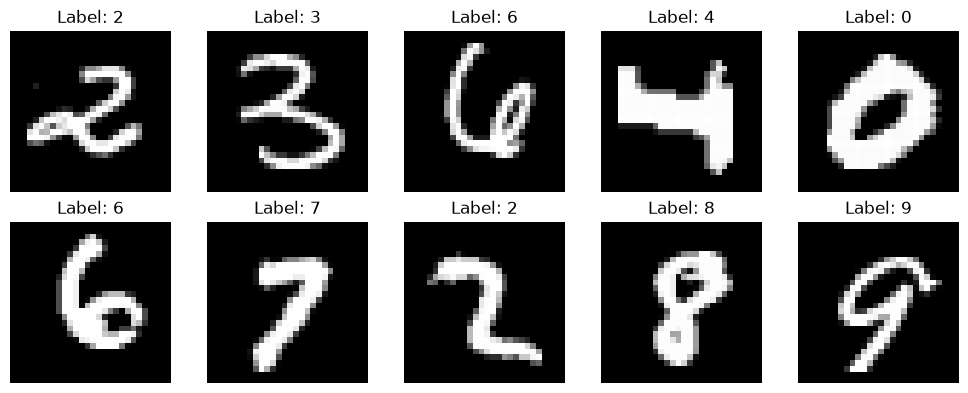

In [5]:
# %% STEP 5: Show some images (data check)
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")
    plt.title("Label: " + str(y_train[i]))
    plt.axis("off")
plt.tight_layout()
plt.show()

In [6]:
# %% STEP 6: CNN model
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # --- Block 1 ---
    layers.Conv2D(32, (3, 3)),          # Convolution (32 filters, 3x3)
    layers.Activation("relu"),          # ReLU
    layers.MaxPooling2D((2, 2)),        # Max Pooling 2x2

    # --- Block 2 ---
    layers.Conv2D(64, (3, 3)),          # Convolution (64 filters)
    layers.Activation("relu"),          # ReLU
    layers.MaxPooling2D((2, 2)),        # Max Pooling

    # --- Classifier ---
    layers.Flatten(),                   # 2D feature maps -> 1D vector
    layers.Dense(128),                  # Fully Connected layer
    layers.Activation("relu"),
    layers.Dropout(0.3),                # overfitting kam karne ke liye
    layers.Dense(10),                   # 10 classes (digits 0-9)
    layers.Activation("softmax"),       # Softmax -> probabilities
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# %% STEP 7: Model compile 
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",   # labels integer (0-9)
    metrics=["accuracy"],
)

In [8]:
# %% STEP 8: Training
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val),
)

Epoch 1/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - accuracy: 0.9178 - loss: 0.2692 - val_accuracy: 0.9779 - val_loss: 0.0764
Epoch 2/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 20s 38ms/step - accuracy: 0.9762 - loss: 0.0800 - val_accuracy: 0.9840 - val_loss: 0.0541
Epoch 3/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 16s 30ms/step - accuracy: 0.9834 - loss: 0.0548 - val_accuracy: 0.9842 - val_loss: 0.0517
Epoch 4/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 12s 23ms/step - accuracy: 0.9858 - loss: 0.0434 - val_accuracy: 0.9833 - val_loss: 0.0540
Epoch 5/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 19s 20ms/step - accuracy: 0.9885 - loss: 0.0353 - val_accuracy: 0.9827 - val_loss: 0.0545
Epoch 6/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9908 - loss: 0.0286 - val_accuracy: 0.9850 - val_loss: 0.0522
Epoch 7/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 11s 20ms/step - accuracy: 0.9921 - loss: 0.0238 - val_accuracy: 0.9877 - val_loss: 0.0428
Epoch 8/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9918 - loss: 0.0236 - 

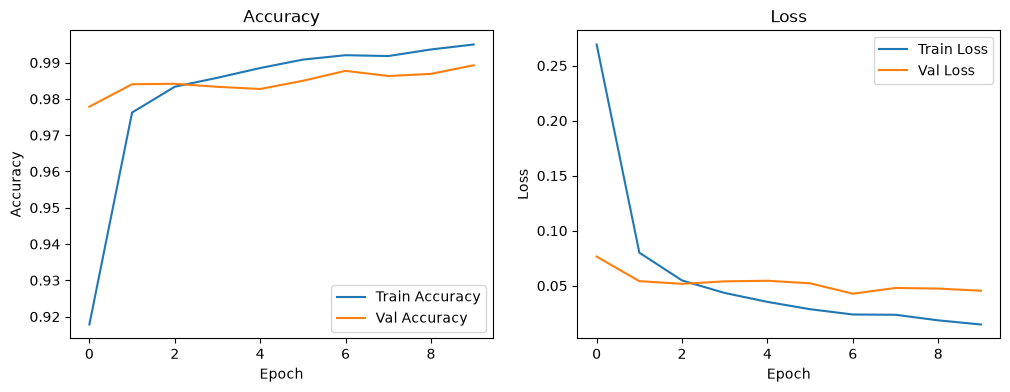

In [11]:
# 9a) Accuracy and Loss graphs on Traning and Validation
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.title("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Loss")
plt.show()

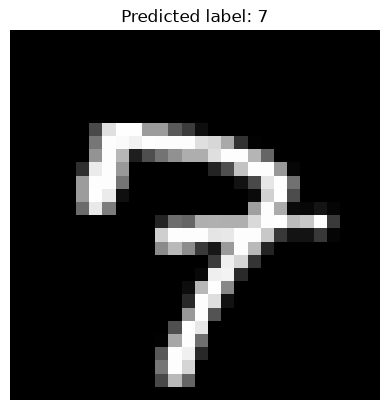

Predicted label: 7


In [15]:
test_df = pd.read_csv(r"test.csv")
X_test = (test_df.values.astype("float32") / 255.0).reshape(-1, 28, 28, 1)

idx = 5                                    # koi bhi image number

probs = model.predict(X_test[idx:idx+1], verbose=0)   # sirf aik image
label = np.argmax(probs)

plt.imshow(X_test[idx].reshape(28, 28), cmap="gray")
plt.title(f"Predicted label: {label}")
plt.axis("off")
plt.show()

print("Predicted label:", label)

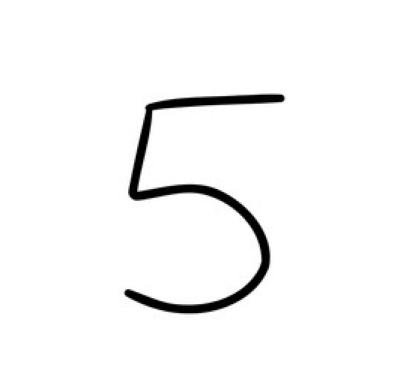

In [16]:
from PIL import Image
path = r"images.png"
img = Image.open(path)

plt.imshow(img)
plt.axis("off")
plt.show()